In [1]:
### Importing packages
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
import pandas as pd
import xarray as xr


In [ ]:
#### QUICK START ####

In [ ]:
### Importing data
# mastapp.site (the old API) was retired in Oct 2026; metadata now lives in the S3 bucket
META_URL = "https://s3.echo.stfc.ac.uk/mast/fairmast-meta"

In [ ]:
### List All Shots
        # Note: in fusion research, a shot is one plasma experiment
# cached locally after the first download (same path as download_fairmast.py)
import os
LOCAL_SHOTS = "fairmast/shots_level2.parquet"
if os.path.exists(LOCAL_SHOTS):
    shots_df = pd.read_parquet(LOCAL_SHOTS)
else:
    shots_df = pd.read_parquet(f"{META_URL}/l2_shots.parquet")
    os.makedirs("fairmast", exist_ok=True)
    shots_df.to_parquet(LOCAL_SHOTS)
shots_df

In [ ]:
### List All Sources
sources_df = pd.read_parquet(f"{META_URL}/l2_sources.parquet")
sources_df

In [ ]:
### List all signals Given a Shot Number
signals_df = pd.read_parquet(f"{META_URL}/l2_signals/signals_30421.parquet")
signals_df

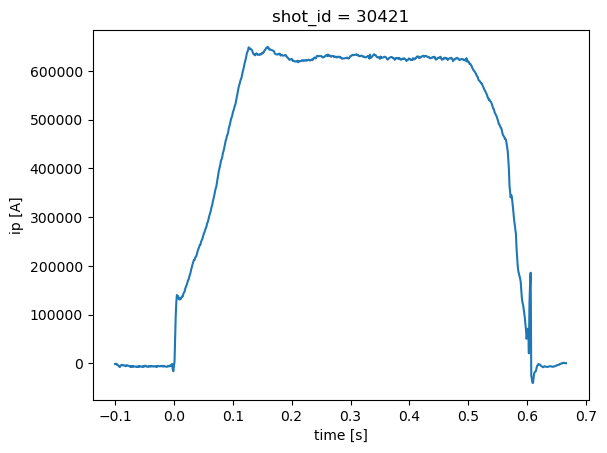

In [ ]:
### Open and plot shot data

dataset = xr.open_zarr(
    "https://s3.echo.stfc.ac.uk/mast/level2/shots/30421.zarr",
    group='summary'
)

dataset['ip'].plot()
plt.show()

In [ ]:
i = 1 
print(len(shots_df.columns))
for col in shots_df.columns:
    print(f"{i} {col}")
    i += 1

NameError: name 'shots_df' is not defined

In [ ]:
print(shots_df[])

Note: you may need to restart the kernel to use updated packages.


The syntax of the command is incorrect.


## Column classification checks

These cells test the claims in `column_classification.md` against the real shot table:

- **Coverage:** every column in the data is classified, and every classified column exists.
- **Completeness and types:** non-null fraction and numeric parse rate, by section. The CPF ingestion code casts columns to strings, so numbers may arrive as text.
- **Sections 1, 3, 4, 6, 7:** identifiers, filters, categoricals, MCS setup and timing behave as the classification assumes.
- **Section 10:** the duplicate and misleading names, resolved by correlating each one with unambiguous reference columns.
- **Units and physics consistency:** magnitudes compared with MAST ranges; τ_E ≈ W / P_heat; β ∝ W / (V B²), which shows why β is LEAKAGE for a W target.

Each check adds a row to `checks`, which is saved to `classification_checks.csv` at the end.

In [ ]:
### Parse column_classification.md into column -> section / subsection
import re
from pathlib import Path

cls_rows, section, subsection = [], None, None
for line in Path("column_classification.md").read_text(encoding="utf8").splitlines():
    if m := re.match(r"^## (\d+)\. (.+)", line):
        section, subsection = f"{m[1]}. {m[2].strip()}", None
    elif m := re.match(r"^### (\d+\.\d+) (.+)", line):
        subsection = f"{m[1]} {m[2].strip()}"
    elif (m := re.match(r"^([a-z0-9_]+): (.*)", line)) and section:
        cls_rows.append(dict(column=m[1], section=section, subsection=subsection or section, doc=m[2]))
cls = pd.DataFrame(cls_rows).drop_duplicates("column").set_index("column")
sec_no = cls.section.str.split(".").str[0].astype(int)

in_data, in_doc = set(shots_df.columns), set(cls.index)
checks = []
def record(check, result, ok):
    checks.append(dict(check=check, result=result, verdict="PASS" if ok else "CHECK"))
    print(f"[{'PASS ' if ok else 'CHECK'}] {check}: {result}")

record("columns classified", f"{len(in_data & in_doc)} of {len(in_data)} data columns", in_data <= in_doc)
print("  in data, not classified:", sorted(in_data - in_doc))
print("  classified, not in data:", sorted(in_doc - in_data))

In [ ]:
### Column summary: dtype, completeness, numeric parse rate, range
MISSING = {"", "None", "none", "nan", "NaN", "NaT", "null"}

def nonnull_mask(s):
    return s.notna() & ~s.astype(str).str.strip().isin(MISSING)

def to_num(s):
    """Numeric view of a column; strings such as '1.2e19' are parsed, everything else -> NaN."""
    if pd.api.types.is_bool_dtype(s) or pd.api.types.is_numeric_dtype(s):
        return s.astype(float)
    if pd.api.types.is_datetime64_any_dtype(s):
        return pd.Series(np.nan, index=s.index)
    return pd.to_numeric(s.astype(str).str.strip().where(nonnull_mask(s)), errors="coerce")

rows = []
for c in shots_df.columns:
    s = shots_df[c]
    nn = nonnull_mask(s)
    x = to_num(s)
    rows.append(dict(
        column=c, dtype=str(s.dtype),
        nonnull_frac=nn.mean(),
        n_unique=s[nn].astype(str).nunique(),
        numeric_frac=(x.notna().sum() / nn.sum()) if nn.sum() else np.nan,
        p01=x.quantile(0.01), median=x.median(), p99=x.quantile(0.99),
        example=str(s[nn].iloc[0])[:40] if nn.any() else "",
    ))
summary = pd.DataFrame(rows).set_index("column").join(cls[["section", "subsection"]])
summary.to_csv("column_summary.csv")

# numeric copy of every mostly-numeric column (used by all later checks)
num = pd.DataFrame({c: to_num(shots_df[c]) for c in summary.index[summary.numeric_frac > 0.95]})
stored_as_text = [c for c in num.columns if not pd.api.types.is_numeric_dtype(shots_df[c])]
record("numeric columns stored as text", f"{len(stored_as_text)} columns (converted in `num`)", True)

by_sec = summary.groupby("section").agg(
    n_cols=("dtype", "size"),
    median_nonnull=("nonnull_frac", "median"),
    n_empty=("nonnull_frac", lambda v: int((v == 0).sum())),
    n_constant=("n_unique", lambda v: int((v <= 1).sum())),
    n_numeric=("numeric_frac", lambda v: int((v > 0.95).sum())),
)
by_sec

In [ ]:
### Figure: completeness by section, and coverage of the physics columns by campaign
Path("figures").mkdir(exist_ok=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw=dict(width_ratios=[1, 1.3]))

order = sorted(summary.section.dropna().unique(), key=lambda s: int(s.split(".")[0]))
for i, sec in enumerate(order):
    v = summary.loc[summary.section == sec, "nonnull_frac"]
    ax1.scatter(v, np.full(len(v), i) + np.random.default_rng(0).uniform(-0.25, 0.25, len(v)), s=10, alpha=0.6)
    ax1.plot([v.median()] * 2, [i - 0.35, i + 0.35], color="k", lw=1.5)
ax1.set_yticks(range(len(order)), [s.split(":")[0] for s in order])
ax1.invert_yaxis()
ax1.set_xlabel("Fraction of shots with a value")
ax1.set_title("Completeness per column (bar = section median)")

phys = summary.index[summary.section.str.startswith("8.", na=False) & summary.index.isin(num.columns)]
cov = num[phys].notna().groupby(shots_df["campaign"]).mean().T
cov = cov.groupby(summary.loc[phys, "subsection"]).mean()
im = ax2.imshow(cov.values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax2.set_xticks(range(cov.shape[1]), cov.columns, rotation=45, ha="right")
ax2.set_yticks(range(cov.shape[0]), [s[:40] for s in cov.index])
ax2.set_title("Physics columns by campaign")
fig.colorbar(im, ax=ax2, label="Fraction of shots with a value")
fig.tight_layout()
fig.savefig("figures/classification_completeness.png", dpi=150)
plt.show()

In [ ]:
### Section 1 (identification) and section 3 (quality flags)
def col(c):
    return num[c] if c in num else None

for c in ["facility", "type_", "context_", "title"]:
    if c in shots_df:
        n = shots_df[c].astype(str).nunique()
        record(f"{c} carries no per-shot information", f"{n} distinct value(s)", n <= 3)

if col("shot_pulse_number") is not None:
    both = num[["shot_pulse_number"]].join(shots_df["shot_id"]).dropna()
    frac = (both.shot_pulse_number == both.shot_id).mean()
    record("shot_pulse_number == shot_id", f"{frac:.1%} of {len(both)} shots", frac > 0.99)

if {"reference_shot", "shot_reference"} <= set(num):
    both = num[["reference_shot", "shot_reference"]].dropna()
    frac = (both.reference_shot == both.shot_reference).mean()
    record("reference_shot == shot_reference", f"{frac:.1%} of {len(both)} shots with both", frac > 0.9)

for c in ["shot_useful", "shot_abort", "shot_end_code"]:
    if c in shots_df:
        print(f"\n{c} value counts:\n", shots_df[c].astype(str).value_counts(dropna=False).head(10).to_string())

if {"shot_useful", "shot_abort"} <= set(num):
    keep = (num.shot_useful == 1) & (num.shot_abort != 1)
    record("shots passing FILTER (useful == 1, abort != 1)", f"{keep.sum()} of {len(keep)}", keep.mean() > 0.3)

In [ ]:
### Section 4 (configuration categoricals) and section 6 (MCS setup)
cat_cols = [c for c in ["campaign", "scenario", "heating", "pellets", "rmp_coil",
                        "current_range", "divertor_config", "plasma_shape", "commissioner"] if c in shots_df]
for c in cat_cols:
    vc = shots_df[c].astype(str).value_counts(dropna=False)
    print(f"{c}: {len(vc)} levels -> {dict(vc.head(6))}")
if {"campaign", "heating"} <= set(shots_df):
    display(pd.crosstab(shots_df.campaign, shots_df.heating.astype(str)))

mcs = summary[summary.section.str.startswith("6.", na=False)]
low_info = mcs[(mcs.nonnull_frac < 0.5) | (mcs.n_unique <= 2)]
record("MCS columns that are sparse (<50% filled) or have <= 2 values (supports IGNORE)",
       f"{len(low_info)} of {len(mcs)}", len(low_info) >= len(mcs) / 2)

In [ ]:
### Section 7 (timing): values in seconds, and events in physical order
t_cols = [c for c in summary.index[summary.section.str.startswith("7.", na=False)] if c in num]
t = num[t_cols]
in_range = ((t > -0.5) & (t < 2.0)).sum() / t.notna().sum()
record("timing columns within -0.5..2 s (MAST pulses last < 1 s)",
       f"{(in_range > 0.95).sum()} of {len(t_cols)} columns have >95% of values in range", (in_range > 0.95).mean() > 0.9)
print("columns mostly outside -0.5..2 s:", list(in_range[in_range <= 0.95].index))

def order_check(a, b, label):
    if {a, b} <= set(num):
        d = num[[a, b]].dropna()
        frac = (d[a] <= d[b] + 1e-3).mean()
        record(label, f"{frac:.1%} of {len(d)} shots", frac > 0.9)

order_check("plasma_flat_top_start_time", "plasma_flat_top_end_time", "flat-top start <= flat-top end")
order_check("plasma_max_plasma_current_time", "plasma_end_time", "time of peak Ip <= plasma end")
order_check("nbi_start_time", "nbi_end_time", "NBI start <= NBI end")

In [ ]:
### Section 10: resolve duplicate and misleading names by correlation with unambiguous columns
def corr_with(target, refs):
    """Spearman correlation of `target` with each reference column (pairwise complete)."""
    out = {}
    for r in refs:
        if target in num and r in num:
            d = num[[target, r]].dropna()
            out[r] = d[target].corr(d[r], method="spearman") if len(d) > 30 else np.nan
    return pd.Series(out, dtype=float)

def resolve(name, hypotheses):
    """hypotheses: {label: reference column that should correlate best if that label is right}"""
    if name not in num:
        print(f"{name}: not in data / not numeric"); return
    c = corr_with(name, list(hypotheses.values()))
    if c.notna().sum() < 2:
        print(f"{name}: reference columns missing"); return
    best = c.idxmax()
    label = [k for k, v in hypotheses.items() if v == best][0]
    record(f"{name} holds", f"{label} (rho: " + ", ".join(f"{k}={c.get(v, np.nan):.2f}" for k, v in hypotheses.items()) + ")",
           c.max() - c.drop(best).max() > 0.1)

# 10.2  time-of-maximum columns with value-like names
resolve("generic_max_poloidal_area",     {"area (value)": "generic_poloidal_area_max_current", "time": "generic_max_plasma_vol_time"})
resolve("generic_min_radius_max_plasma", {"minor radius (value)": "generic_minor_radius_max_current", "time": "generic_max_plasma_vol_time"})
resolve("generic_max_beta_mhd",          {"beta (value)": "generic_beta_time_max_current", "time": "generic_max_mhd_energy_time"})
resolve("generic_max_beta_poloidal_mhd", {"beta_p (value)": "generic_beta_poloidal_max_current", "time": "generic_max_mhd_energy_time"})
# 10.3  value columns with "time" in the name
resolve("generic_max_energy_time",       {"tau_E (value)": "generic_energy_time_max_current", "time": "generic_max_total_energy_time"})
# 10.1  duplicate names
resolve("nbi_power_max_current",         {"total SS+SW power": "nbi_power_max_power", "SW-beam power": "nbi_power_max_sw"})
resolve("nbi_injected_energy_ss_max_current", {"SS-beam energy": "nbi_total_injected_energy_ss", "SW-beam energy": "nbi_total_injected_energy_sw"})
resolve("nbi_end_time_ss",               {"SS end time": "nbi_ss_start_time", "SW end time": "nbi_sw_start_time"})
resolve("thomson_line_avg_density_co2",  {"CO2 line average": "thomson_density_line_max_current", "YAG average": "thomson_density_max_current"})

# extra test for the most important duplicate: total power must be >= SS-beam power
if {"nbi_power_max_current", "nbi_power_ss_max_current"} <= set(num):
    d = num[["nbi_power_max_current", "nbi_power_ss_max_current"]].dropna()
    d = d[d.nbi_power_ss_max_current > 0]
    frac = (d.nbi_power_max_current >= 0.99 * d.nbi_power_ss_max_current).mean()
    record("nbi_power_max_current >= SS power (true if it is the total)", f"{frac:.1%} of {len(d)} SS-heated shots", frac > 0.95)

In [ ]:
### Units: compare medians with MAST ranges (R0 ~ 0.85 m, a ~ 0.6 m, B_T ~ 0.5 T, Ip <= 1.5 MA, P_NBI <= 4 MW)
unit_ranges = {
    "plasma_max_current":               {"A": (1e5, 2e6), "kA": (100, 2000), "MA": (0.1, 2)},
    "generic_toroidal_max_current":     {"T": (0.2, 0.9)},
    "generic_geo_radius_max_current":   {"m": (0.5, 1.2)},
    "generic_minor_radius_max_current": {"m": (0.3, 0.8)},
    "generic_plasma_vol_max_current":   {"m^3": (2, 15)},
    "thomson_density_max_current":      {"m^-3": (1e18, 2e20), "1e19 m^-3": (0.1, 20)},
    "thomson_density_line_max_current": {"m^-2": (1e18, 3e20), "1e19 m^-2": (0.1, 30)},
    "thomson_temp_max_current":         {"eV": (30, 3000), "keV": (0.03, 3)},
    "generic_energy_current_max":       {"J": (500, 3e5), "kJ": (0.5, 300)},
    "generic_energy_time_max_current":  {"s": (2e-4, 0.3), "ms": (0.2, 300)},
    "nbi_power_max_power":              {"W": (5e4, 6e6), "kW": (50, 6000), "MW": (0.05, 6)},
    "ohmnic_heating_max_current":       {"W": (1e4, 1e7), "kW": (10, 1e4), "MW": (0.01, 10)},
}
to_si = {"A": 1, "kA": 1e3, "MA": 1e6, "T": 1, "m": 1, "m^3": 1, "m^-3": 1, "1e19 m^-3": 1e19, "m^-2": 1, "1e19 m^-2": 1e19,
         "eV": 1, "keV": 1e3, "J": 1, "kJ": 1e3, "s": 1, "ms": 1e-3, "W": 1, "kW": 1e3, "MW": 1e6}
unit_guess = {}
for c, cands in unit_ranges.items():
    if c not in num: continue
    med = num[c][num[c] > 0].median()
    hits = [u for u, (lo, hi) in cands.items() if lo <= med <= hi]
    unit_guess[c] = hits[0] if len(hits) == 1 else None
    record(f"unit of {c}", f"median {med:.3g} -> {hits or 'no candidate fits'}", len(hits) == 1)

In [ ]:
### Physics consistency: tau_E ~ W / P_heat (ohmic-only shots), and beta ~ W / (V B^2)
def si(c):
    return num[c] * to_si[unit_guess[c]] if unit_guess.get(c) else None

W, tau, P_ohm = si("generic_energy_current_max"), si("generic_energy_time_max_current"), si("ohmnic_heating_max_current")
P_nbi = si("nbi_power_max_power")
if W is not None and tau is not None and P_ohm is not None:
    ohmic_only = (P_nbi.fillna(0) <= 0) if P_nbi is not None else pd.Series(True, index=num.index)
    ratio = (tau / (W / P_ohm))[ohmic_only & (W > 0) & (P_ohm > 0) & (tau > 0)].dropna()
    record("tau_E / (W / P_ohm) on ohmic-only shots (~1 means units and definitions agree)",
           f"median {ratio.median():.2f}, IQR {ratio.quantile(.25):.2f}-{ratio.quantile(.75):.2f}, n={len(ratio)}",
           0.5 < ratio.median() < 2)

need = ["generic_beta_time_max_current", "generic_energy_current_max", "generic_plasma_vol_max_current", "generic_toroidal_max_current"]
if set(need) <= set(num):
    d = np.log(num[need].where(num[need] > 0)).dropna()
    X = np.column_stack([np.ones(len(d)), d.iloc[:, 1:].values])
    coef, *_ = np.linalg.lstsq(X, d.iloc[:, 0].values, rcond=None)
    r2 = 1 - np.var(d.iloc[:, 0] - X @ coef) / np.var(d.iloc[:, 0])
    record("log beta ~ log W, log V, log B_T (expect exponents +1, -1, -2; high R^2 -> beta is LEAKAGE for W)",
           f"exponents {coef[1]:+.2f}, {coef[2]:+.2f}, {coef[3]:+.2f}; R^2={r2:.3f}; n={len(d)}", r2 > 0.8)

In [ ]:
### Figure: correlation of each physics column at the peak-Ip slice with log W_MHD
target = "generic_energy_current_max"
if target in num:
    sl = [c for c in num.columns if c.endswith("_max_current") and c != target and str(summary.loc[c, "section"]).startswith("8.")]
    logW = np.log(num[target].where(num[target] > 0))
    rho = pd.Series({c: logW.corr(num[c], method="spearman") for c in sl}).dropna().sort_values()
    sub = summary.loc[rho.index, "subsection"]
    colors = {s: f"C{i}" for i, s in enumerate(sorted(sub.unique()))}

    fig, ax = plt.subplots(figsize=(8, 0.28 * len(rho) + 1.5))
    ax.barh(range(len(rho)), rho.values, color=[colors[s] for s in sub])
    ax.set_yticks(range(len(rho)), rho.index, fontsize=8)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlabel("Spearman correlation with W_MHD at peak Ip")
    ax.set_title("Peak-Ip slice: candidate features vs. target")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=c, label=s.split(" (")[0]) for s, c in colors.items()], fontsize=7,
              loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
    fig.tight_layout()
    fig.savefig("figures/correlation_with_W.png", dpi=150)
    plt.show()

In [ ]:
### All check results
checks_df = pd.DataFrame(checks)
checks_df.to_csv("classification_checks.csv", index=False)
pd.set_option("display.max_colwidth", 140)
checks_df